# Stream B — 04 Results

Creates Stream B summary tables and figures from `stream_b_predictions.csv`.


In [1]:
from pathlib import Path
import sys, os, json, pickle, time, math, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

def find_repo_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "data").exists() and (q / "src").exists():
            return q
    raise RuntimeError("Could not find repo root. Run this notebook inside eve-rag.")

ROOT = find_repo_root()
sys.path.insert(0, str(ROOT))

from src.utils.paths import (
    MANIFESTS, PROCESSED_IMAGES, STREAM_B_CACHE,
    TRAIN_MANIFEST, VAL_MANIFEST, TEST_MANIFEST,
    VERITE_TEST_MANIFEST, MMFAKEBENCH_VAL_MANIFEST, MMFAKEBENCH_TEST_MANIFEST,
    ALL_MANIFEST, FIGURES, TABLES
)

STREAM_B_CACHE.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("STREAM_B_CACHE:", STREAM_B_CACHE)


ROOT: E:\eve-rag
STREAM_B_CACHE: E:\eve-rag\cache\stream_b


In [2]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

FINAL_DIR = STREAM_B_CACHE / "final"
pred_path = FINAL_DIR / "stream_b_predictions.csv"
results_path = TABLES / "stream_b_results.csv"

if not pred_path.exists():
    raise FileNotFoundError(f"Missing {pred_path}. Run lora_stage2_fixed_updated.ipynb first.")

pred = pd.read_csv(pred_path, low_memory=False)
results = pd.read_csv(results_path, low_memory=False) if results_path.exists() else None

print(pred.shape)
display(results)


(24909, 7)


,dataset,acc,precision,recall,f1,auroc
0,newsclippings_val,66.22,67.97,61.33,64.48,73.42
1,newsclippings_test,65.87,67.60,60.96,64.11,73.91
2,mmfakebench_test,46.95,82.38,30.80,44.84,63.35
3,verite_test_local,63.77,66.32,92.49,77.25,49.12


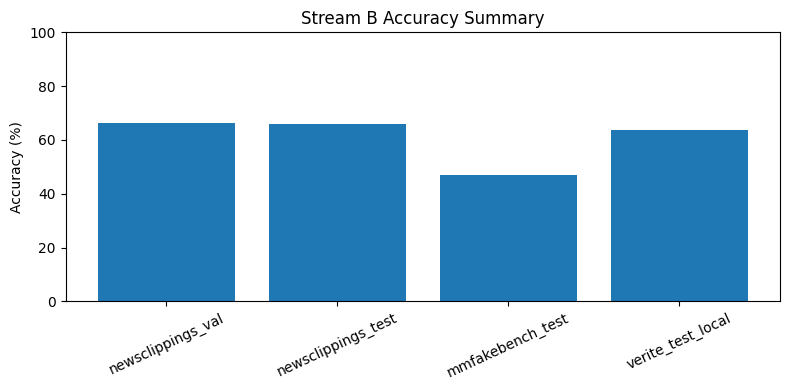

In [3]:
# Accuracy summary bar.
if results is not None and not results.empty:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(results["dataset"], results["acc"])
    ax.set_title("Stream B Accuracy Summary")
    ax.set_ylabel("Accuracy (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    fig.savefig(FIGURES / "stream_b_summary_bar.png", dpi=200, bbox_inches="tight")
    plt.show()


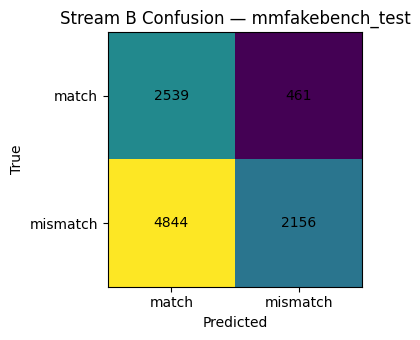

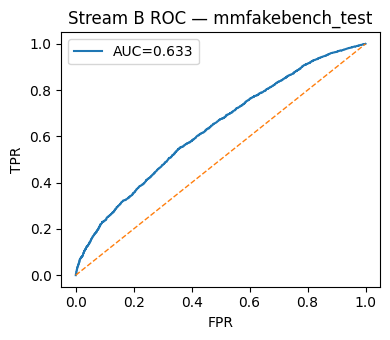

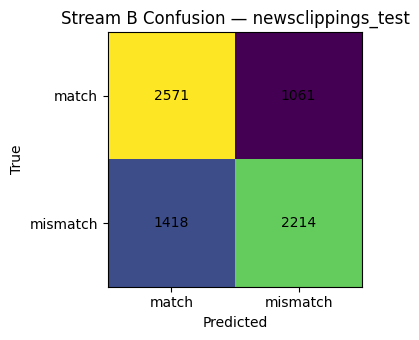

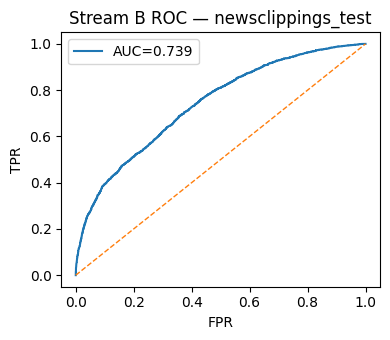

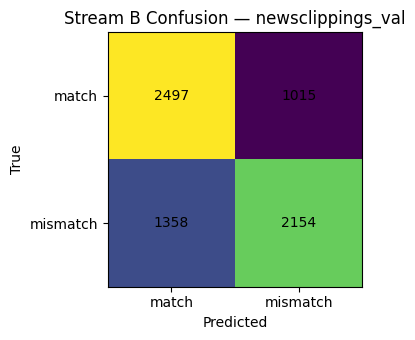

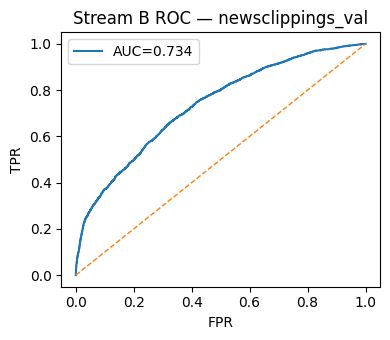

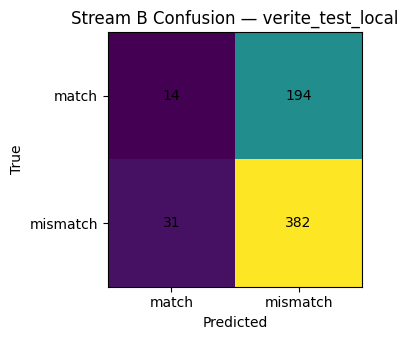

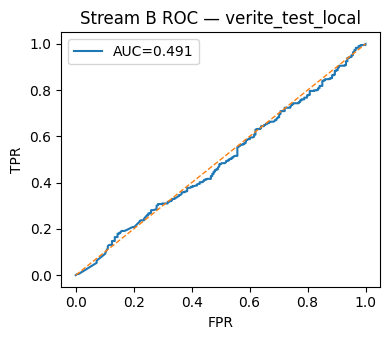

In [4]:
# Confusion and ROC per eval dataset.
for eval_name, sub in pred.groupby("eval_dataset"):
    y = sub["label"].astype(int).values
    yhat = sub["stream_b_pred"].astype(int).values
    score = sub["stream_b_score"].astype(float).values

    cm = confusion_matrix(y, yhat)
    fig, ax = plt.subplots(figsize=(4, 3.5))
    ax.imshow(cm)
    ax.set_title(f"Stream B Confusion — {eval_name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["match", "mismatch"])
    ax.set_yticklabels(["match", "mismatch"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    fig.tight_layout()
    fig.savefig(FIGURES / f"stream_b_confusion_{eval_name}.png", dpi=200, bbox_inches="tight")
    plt.show()

    if len(np.unique(y)) > 1:
        fpr, tpr, _ = roc_curve(y, score)
        auc = roc_auc_score(y, score)
        fig, ax = plt.subplots(figsize=(4, 3.5))
        ax.plot(fpr, tpr, label=f"AUC={auc:.3f}")
        ax.plot([0, 1], [0, 1], "--", linewidth=1)
        ax.set_title(f"Stream B ROC — {eval_name}")
        ax.set_xlabel("FPR")
        ax.set_ylabel("TPR")
        ax.legend()
        fig.tight_layout()
        fig.savefig(FIGURES / f"stream_b_roc_{eval_name}.png", dpi=200, bbox_inches="tight")
        plt.show()


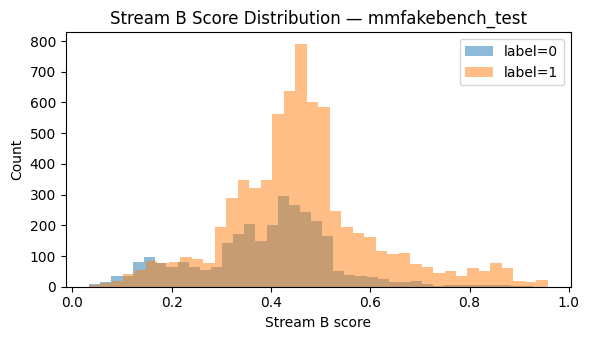

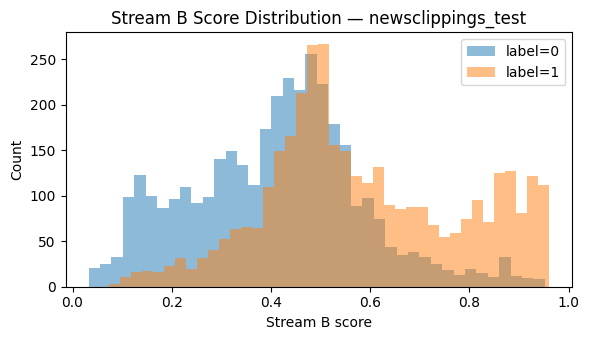

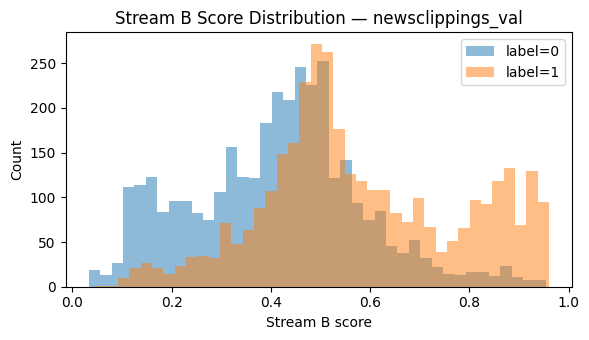

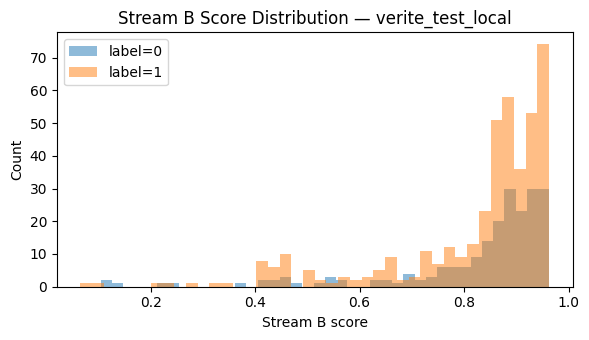

In [5]:
# Score distributions.
for eval_name, sub in pred.groupby("eval_dataset"):
    fig, ax = plt.subplots(figsize=(6, 3.5))
    for label, part in sub.groupby("label"):
        ax.hist(part["stream_b_score"].astype(float), bins=40, alpha=0.5, label=f"label={label}")
    ax.set_title(f"Stream B Score Distribution — {eval_name}")
    ax.set_xlabel("Stream B score")
    ax.set_ylabel("Count")
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIGURES / f"stream_b_score_distribution_{eval_name}.png", dpi=200, bbox_inches="tight")
    plt.show()


In [6]:
print("=" * 60)
print("Stream B reporting complete.")
print("Figures saved to:", FIGURES)
print("Tables saved to:", TABLES)
print("=" * 60)


Stream B reporting complete.
Figures saved to: E:\eve-rag\paper\figures
Tables saved to: E:\eve-rag\paper\tables
